# EDA: evaluación de coches

## 1. Introducción y objetivo

Analizamos las **1.728 combinaciones** del conjunto `car.data` para estudiar cómo se relacionan las características de un coche con su clasificación (`unacc`, `acc`, `good`, `vgood`). No son mediciones de coches reales. Fuente: `car.names`.

## 2. Carga y perfilado

Asignamos los siete nombres porque `car.data` no tiene encabezados: seis características y la clasificación final.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

columnas = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
df = pd.read_csv("car.data", header=None, names=columnas, dtype=str)
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [2]:
print("Filas y columnas:", df.shape)
df.info()
print("Valores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

Filas y columnas: (1728, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1728 non-null   str  
 1   maint     1728 non-null   str  
 2   doors     1728 non-null   str  
 3   persons   1728 non-null   str  
 4   lug_boot  1728 non-null   str  
 5   safety    1728 non-null   str  
 6   class     1728 non-null   str  
dtypes: str(7)
memory usage: 133.5 KB
Valores nulos: 0
Filas duplicadas: 0


**Resultado:** 1.728 filas, 7 columnas, sin nulos ni registros duplicados. Las siete columnas contienen categorías.

## 3. Limpieza y preparación

Comprobamos que los valores de cada columna coincidan con los permitidos en `car.names` y `car.c45-names`.

In [3]:
permitidos = {
    "buying": {"vhigh", "high", "med", "low"},
    "maint": {"vhigh", "high", "med", "low"},
    "doors": {"2", "3", "4", "5more"},
    "persons": {"2", "4", "more"},
    "lug_boot": {"small", "med", "big"},
    "safety": {"low", "med", "high"},
    "class": {"unacc", "acc", "good", "vgood"}
}
print("Valores no permitidos:")
print(pd.Series({col: (~df[col].isin(valores)).sum()
                 for col, valores in permitidos.items()}))

Valores no permitidos:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


**Decisión:** no hay categorías incorrectas ni datos que limpiar. No se aplica búsqueda numérica de valores atípicos porque las variables son categóricas.

## 4. Análisis exploratorio

### 4.1. Univariante: clasificación de los coches

       frecuencia  porcentaje
class                        
unacc        1210        70.0
acc           384        22.2
good           69         4.0
vgood          65         3.8


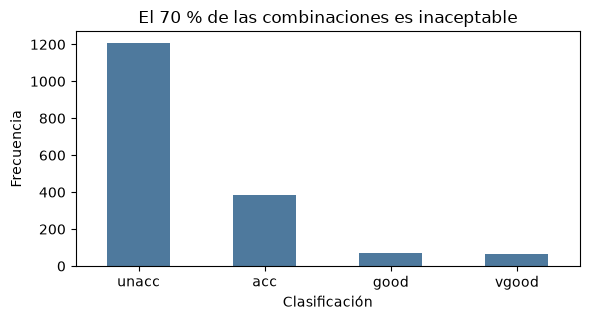

In [4]:
orden = ["unacc", "acc", "good", "vgood"]
cuentas = df["class"].value_counts().reindex(orden)
print(pd.DataFrame({"frecuencia": cuentas, "porcentaje": (cuentas / len(df) * 100).round(1)}))
ax = cuentas.plot.bar(figsize=(6, 3.3), color="#4E799D", rot=0)
ax.set(title="El 70 % de las combinaciones es inaceptable", xlabel="Clasificación", ylabel="Frecuencia")
plt.tight_layout()
plt.show()

**Hallazgo:** `unacc` representa 1.210 casos (70,0 %); `vgood`, solo 65 (3,8 %).

### 4.2. Bivariante: seguridad y clasificación

class   unacc   acc  good  vgood
safety                          
low     100.0   0.0   0.0    0.0
med      62.0  31.2   6.8    0.0
high     48.1  35.4   5.2   11.3


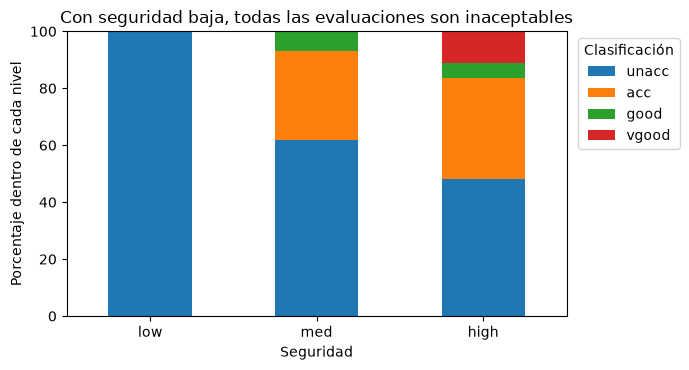

In [5]:
tabla = pd.crosstab(df["safety"], df["class"], normalize="index").mul(100)
tabla = tabla.reindex(index=["low", "med", "high"], columns=orden)
print(tabla.round(1))
ax = tabla.plot.bar(stacked=True, figsize=(7, 3.8), rot=0)
ax.set(title="Con seguridad baja, todas las evaluaciones son inaceptables",
       xlabel="Seguridad", ylabel="Porcentaje dentro de cada nivel")
ax.legend(title="Clasificación", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Hallazgo:** el 100 % de los 576 registros con seguridad `low` es `unacc`. La seguridad está claramente asociada a la clasificación.

### 4.3. Multivariante: seguridad, plazas y evaluación

persons    2     4  more
safety                  
low      0.0   0.0   0.0
med      0.0  56.2  57.8
high     0.0  81.2  74.5


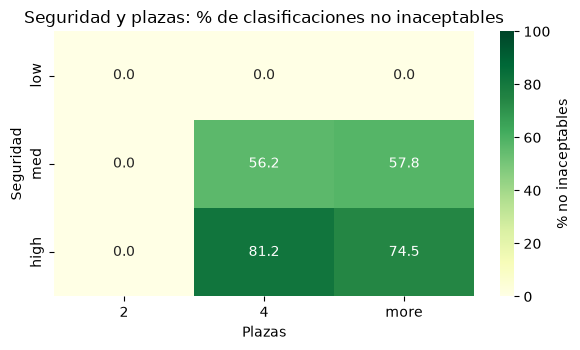

In [6]:
aux = df.assign(aceptable=df["class"] != "unacc")
matriz = (aux.groupby(["safety", "persons"])["aceptable"].mean() * 100).unstack()
matriz = matriz.reindex(index=["low", "med", "high"], columns=["2", "4", "more"])
print(matriz.round(1))
plt.figure(figsize=(6, 3.6))
sns.heatmap(matriz, annot=True, fmt=".1f", cmap="YlGn", vmin=0, vmax=100,
            cbar_kws={"label": "% no inaceptables"})
plt.title("Seguridad y plazas: % de clasificaciones no inaceptables")
plt.xlabel("Plazas"); plt.ylabel("Seguridad")
plt.tight_layout()
plt.show()

**Hallazgo:** todas las combinaciones con dos plazas o seguridad baja son `unacc`. Con seguridad alta y cuatro plazas, el 81,2 % no es `unacc`. No usamos correlación de Pearson porque los valores son categorías.

## 5. Conclusiones

- Predomina la clasificación **inaceptable** (70,0 %).
- **Seguridad baja** y **dos plazas** siempre coinciden con `unacc` en este conjunto.
- La combinación de **seguridad y plazas** permite distinguir mejor los resultados que observar solo un atributo.

Las asociaciones describen el sistema de evaluación del archivo, no la calidad real de los automóviles.